<a href="https://colab.research.google.com/github/DilemmaFixer3/MZKN_labs/blob/main/%D0%9B%D0%A05_%D0%92%D0%B0%D1%80%D1%96%D0%B0%D0%BD%D1%821.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №5. Сегментація клієнтів і прогнозування відтоку
**Варіант 1.** Ознаки для кластеризації: `age, tenure_months, sessions_per_month, avg_session_min, nps`.
Ансамблева модель: **випадковий ліс**. Фільтр для завдання №3: **plan = базовий**.

Файл `customers.csv` має лежати поруч із ноутбуком.

In [1]:
# === Імпорт бібліотек ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_val_predict)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 150)
RS = 42                      # фіксуємо випадковість для відтворюваності

## Завдання №1. Огляд даних

In [2]:
df_raw = pd.read_csv("customers.csv")
print("Розмір:", df_raw.shape)
df_raw.info()

Розмір: (2000, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         2000 non-null   object 
 1   age                 2000 non-null   int64  
 2   city_size           2000 non-null   object 
 3   plan                2000 non-null   object 
 4   tenure_months       2000 non-null   int64  
 5   sessions_per_month  2000 non-null   float64
 6   avg_session_min     1970 non-null   float64
 7   courses_started     2000 non-null   int64  
 8   courses_completed   2000 non-null   int64  
 9   support_tickets     2000 non-null   int64  
 10  late_payments       2000 non-null   int64  
 11  discount            2000 non-null   int64  
 12  device              2000 non-null   object 
 13  nps                 1970 non-null   float64
 14  churn               2000 non-null   int64  
dtypes: float64(3), int64(8), object(4)
m

In [3]:
# Пропуски і логічні перевірки
na = df_raw.isna().sum()
print("Пропуски:\n", na[na > 0], sep="")
print("\nЗавершено курсів більше, ніж розпочато:",
      (df_raw["courses_completed"] > df_raw["courses_started"]).sum())
print("NPS поза межами 0–10:", (~df_raw["nps"].dropna().between(0, 10)).sum())
print("Повторів customer_id:", df_raw["customer_id"].duplicated().sum())
bad = (df_raw["sessions_per_month"] == 0) & (df_raw["avg_session_min"] > 0)
print("0 сеансів, але тривалість сеансу > 0 хв:", bad.sum())

Пропуски:
avg_session_min    30
nps                30
dtype: int64

Завершено курсів більше, ніж розпочато: 0
NPS поза межами 0–10: 0
Повторів customer_id: 0
0 сеансів, але тривалість сеансу > 0 хв: 82


**Рішення щодо проблем у даних**

| Проблема | Кількість | Рішення | Обґрунтування |
|---|---|---|---|
| 0 сеансів на місяць, але тривалість сеансу > 0 хв | 82 | `avg_session_min` = 0 | якщо сеансів не було, їх середня тривалість не може бути додатною |
| пропуски `avg_session_min` | 30 (1,5 %) | медіана | пропусків мало; медіана стійка до викидів (метод ЛР №3) |
| пропуски `nps` | 30 (1,5 %) | медіана | так само; NPS — ціле число 0–10, медіана теж ціла |

In [4]:
df = df_raw.copy()
# 1) немає сеансів -> тривалість сеансу 0 (для 3 таких клієнтів тривалість була пропущена)
df.loc[df["sessions_per_month"] == 0, "avg_session_min"] = 0
# 2) решту пропусків заповнюємо медіаною
for col in ["avg_session_min", "nps"]:
    med = df[col].median()
    df[col] = df[col].fillna(med)
    print(f"{col}: пропуски заповнено медіаною {med}")
print("Пропусків після обробки:", df.isna().sum().sum())
df.describe().round(2).T

avg_session_min: пропуски заповнено медіаною 27.0
nps: пропуски заповнено медіаною 7.0
Пропусків після обробки: 0


,count,mean,std,min,25%,50%,75%,max
age,2000.0,37.98,12.48,17.0,27.0,38.0,49.0,59.0
tenure_months,2000.0,24.09,13.52,1.0,12.0,24.0,36.0,47.0
sessions_per_month,2000.0,9.43,5.00,0.0,6.0,9.0,13.0,26.0
avg_session_min,2000.0,27.19,12.89,0.0,19.0,27.0,36.0,65.0
courses_started,2000.0,4.05,1.99,1.0,2.0,4.0,6.0,7.0
courses_completed,2000.0,1.85,1.55,0.0,1.0,1.5,3.0,7.0
support_tickets,2000.0,0.58,0.78,0.0,0.0,0.0,1.0,4.0
late_payments,2000.0,0.40,0.65,0.0,0.0,0.0,1.0,4.0
discount,2000.0,9.98,11.55,0.0,0.0,10.0,20.0,30.0
nps,2000.0,7.10,2.06,0.0,6.0,7.0,9.0,10.0


In [5]:
# Частка відтоку і дисбаланс класів
print(df["churn"].value_counts().rename({0: "залишився (0)", 1: "пішов (1)"}))
print("\nЧастка відтоку:", round(df["churn"].mean(), 3))
print("Співвідношення класів 0 : 1 =", round((1 - df["churn"].mean()) / df["churn"].mean(), 1), ": 1")

churn
залишився (0)    1569
пішов (1)         431
Name: count, dtype: int64

Частка відтоку: 0.216
Співвідношення класів 0 : 1 = 3.6 : 1


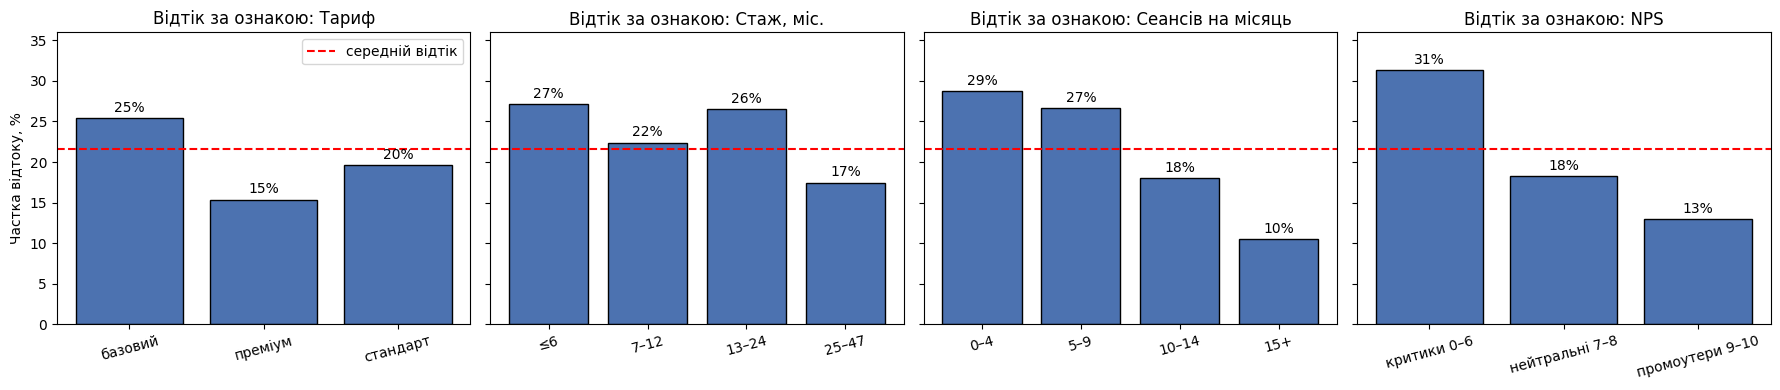

In [6]:
# Зв'язок відтоку з тарифом, стажем, активністю та NPS
df["стаж"] = pd.cut(df["tenure_months"], [0, 6, 12, 24, 48], labels=["≤6", "7–12", "13–24", "25–47"])
df["активність"] = pd.cut(df["sessions_per_month"], [-1, 4, 9, 14, 30], labels=["0–4", "5–9", "10–14", "15+"])
df["група NPS"] = pd.cut(df["nps"], [-1, 6, 8, 10], labels=["критики 0–6", "нейтральні 7–8", "промоутери 9–10"])

fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for a, col, title in zip(ax, ["plan", "стаж", "активність", "група NPS"],
                         ["Тариф", "Стаж, міс.", "Сеансів на місяць", "NPS"]):
    s = df.groupby(col, observed=True)["churn"].mean() * 100
    a.bar(s.index.astype(str), s.values, color="#4C72B0", edgecolor="k")
    for i, v in enumerate(s.values):
        a.text(i, v + 0.8, f"{v:.0f}%", ha="center")
    a.axhline(df["churn"].mean() * 100, color="r", ls="--", label="середній відтік")
    a.set_title(f"Відтік за ознакою: {title}"); a.tick_params(axis="x", rotation=15)
ax[0].set_ylabel("Частка відтоку, %"); ax[0].set_ylim(0, 36); ax[0].legend()
plt.tight_layout(); plt.show()

## Завдання №2. Сегментація клієнтів

In [7]:
CL_FEATS = ["age", "tenure_months", "sessions_per_month", "avg_session_min", "nps"]   # варіант 1
Z = StandardScaler().fit_transform(df[CL_FEATS])     # усі ознаки числові -> лише масштабування

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))
k_table = pd.DataFrame({"k": ks, "inertia": np.round(inertia, 0),
                        "зменшення inertia": np.r_[np.nan, -np.diff(inertia)].round(0),
                        "силует": np.round(sil, 3)}).set_index("k")
k_table

,inertia,зменшення inertia,силует
k,,,
2,8448.0,NaN,0.149
3,7412.0,1036.0,0.147
4,6647.0,765.0,0.152
5,6054.0,594.0,0.158
6,5580.0,473.0,0.160
7,5229.0,351.0,0.161
8,4911.0,318.0,0.167


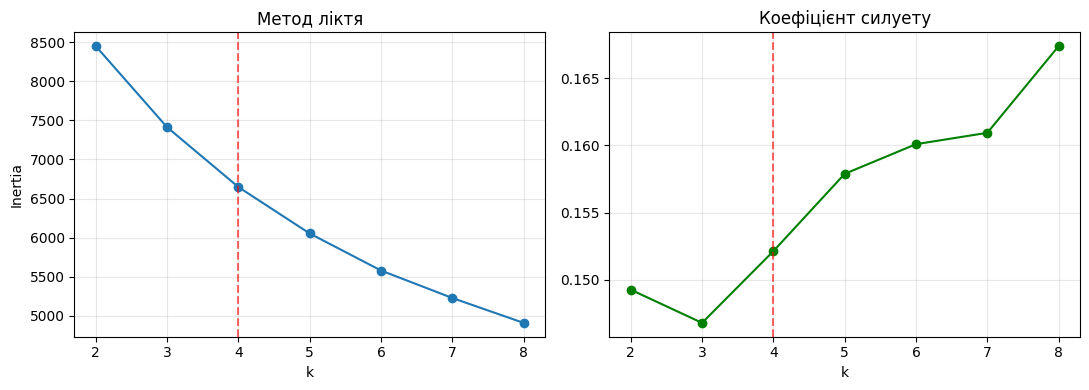

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Метод ліктя"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(ks, sil, "o-", color="g"); ax[1].set_title("Коефіцієнт силуету"); ax[1].set_xlabel("k")
for a in ax: a.axvline(4, color="r", ls="--", alpha=0.6); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Вибір k.** Силует для всіх k від 2 до 8 низький і майже однаковий (0,15–0,17): клієнти не утворюють чітко відокремлених груп,
тому силует не дає однозначної відповіді (невелике зростання до k = 8 — це дроблення на дрібні групи). На графіку ліктя
зменшення inertia сповільнюється після k = 4 (−1036, −765, далі −594, −473, −351). Обираємо **k = 4**: це «лікоть», а кластери змістовно різні і добре описуються
(див. профіль), чого не скажеш про 7–8 дрібних груп.

In [9]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=RS).fit(Z)
df["cluster"] = km.labels_

profile = df.groupby("cluster")[CL_FEATS + ["churn"]].mean().round(2)
profile["size"] = df["cluster"].value_counts().sort_index()
profile["share_%"] = (profile["size"] / len(df) * 100).round(1)
profile

,age,tenure_months,sessions_per_month,avg_session_min,nps,churn,size,share_%
cluster,,,,,,,,
0,25.37,24.64,12.45,27.76,7.89,0.14,519,26.0
1,46.34,11.28,9.95,30.05,7.38,0.24,550,27.5
2,46.28,37.05,9.94,31.99,7.11,0.16,519,26.0
3,32.28,24.19,4.30,16.63,5.70,0.34,412,20.6


In [10]:
# Склад кластерів за тарифом (частки в рядку)
pd.crosstab(df["cluster"], df["plan"], normalize="index").round(2)

plan,базовий,преміум,стандарт
cluster,,,
0,0.39,0.22,0.39
1,0.50,0.16,0.33
2,0.42,0.17,0.42
3,0.52,0.07,0.41


In [11]:
# Назви сегментів — з чисел профілю (визначаємо за правилами, щоб назви не залежали від нумерації кластерів)
p_ = profile.copy()
c_passive = p_["sessions_per_month"].idxmin()                    # найменше сеансів і найнижчий NPS
rest = p_.drop(c_passive)
c_young = rest["age"].idxmin()                                   # наймолодші, найактивніші
rest = rest.drop(c_young)
c_loyal = rest["tenure_months"].idxmax()                         # найбільший стаж
c_new = rest.drop(c_loyal).index[0]                              # старші за віком, малий стаж
SEG = {int(c_passive): "Незадоволені пасивні", int(c_young): "Молоде активне ядро",
       int(c_loyal): "Досвідчені лояльні", int(c_new): "Старші новачки"}
print(SEG)
df["segment"] = df["cluster"].map(SEG)
seg_table = profile.rename(index=SEG)
seg_table

{3: 'Незадоволені пасивні', 0: 'Молоде активне ядро', 2: 'Досвідчені лояльні', 1: 'Старші новачки'}


,age,tenure_months,sessions_per_month,avg_session_min,nps,churn,size,share_%
cluster,,,,,,,,
Молоде активне ядро,25.37,24.64,12.45,27.76,7.89,0.14,519,26.0
Старші новачки,46.34,11.28,9.95,30.05,7.38,0.24,550,27.5
Досвідчені лояльні,46.28,37.05,9.94,31.99,7.11,0.16,519,26.0
Незадоволені пасивні,32.28,24.19,4.30,16.63,5.70,0.34,412,20.6


Пояснена дисперсія PC1, PC2: [0.244 0.202]  разом: 0.447

Внесок ознак у компоненти:
      age  tenure_months  sessions_per_month  avg_session_min   nps
PC1  0.16           0.00                0.66             0.55  0.48
PC2  0.29           0.84                0.00             0.25 -0.39


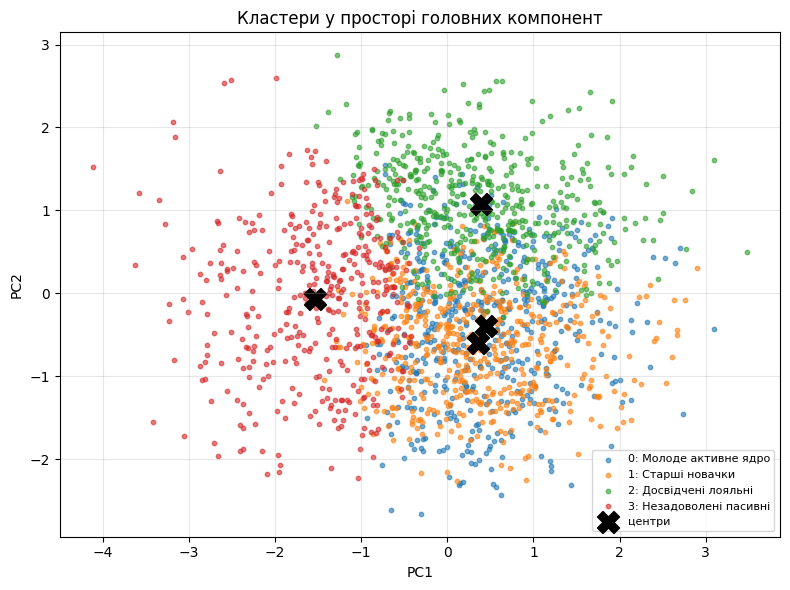

In [12]:
pca = PCA(n_components=2, random_state=RS)
P = pca.fit_transform(Z)
print("Пояснена дисперсія PC1, PC2:", pca.explained_variance_ratio_.round(3),
      " разом:", round(pca.explained_variance_ratio_.sum(), 3))
print("\nВнесок ознак у компоненти:")
print(pd.DataFrame(pca.components_.round(2), index=["PC1", "PC2"], columns=CL_FEATS))

fig, ax = plt.subplots(figsize=(8, 6))
for c in range(K):
    m = df["cluster"] == c
    ax.scatter(P[m, 0], P[m, 1], s=10, alpha=0.6, label=f"{c}: {SEG[c]}")
C = pca.transform(km.cluster_centers_)
ax.scatter(C[:, 0], C[:, 1], marker="X", s=250, c="k", label="центри")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Кластери у просторі головних компонент")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

Дві головні компоненти пояснюють лише ≈45 % дисперсії (< 50 %), тому двовимірна картина — грубе наближення:
кластери на ній частково перекриваються, хоча в повному 5-вимірному просторі розділені краще.
PC1 — це «активність і задоволеність» (сеанси, тривалість, NPS), PC2 — переважно стаж.

## Завдання №3. Прогнозування відтоку (фільтр: plan = базовий)

In [13]:
base_df = df[df["plan"] == "базовий"].copy()
print("Клієнтів з базовим тарифом:", len(base_df), " відтік:", round(base_df["churn"].mean(), 3))

# ознаки: усі вихідні, крім ідентифікатора, цілі, тарифу (після фільтра він однаковий) і службових стовпців
drop = ["customer_id", "churn", "plan", "cluster", "segment", "стаж", "активність", "група NPS"]
X = pd.get_dummies(base_df.drop(columns=drop), drop_first=True).astype(float)
y = base_df["churn"]
print("Ознаки:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RS)
print("Навчальна:", X_train.shape, " відтік", round(y_train.mean(), 3))
print("Тестова:  ", X_test.shape, " відтік", round(y_test.mean(), 3))

Клієнтів з базовим тарифом: 910  відтік: 0.254
Ознаки: ['age', 'tenure_months', 'sessions_per_month', 'avg_session_min', 'courses_started', 'courses_completed', 'support_tickets', 'late_payments', 'discount', 'nps', 'city_size_мале', 'city_size_середнє', 'device_мобільний']
Навчальна: (637, 13)  відтік 0.254
Тестова:   (273, 13)  відтік 0.253


In [14]:
# Базова модель: одне дерево з обмеженою глибиною
base = DecisionTreeClassifier(max_depth=4, random_state=RS).fit(X_train, y_train)

# Випадковий ліс: підбір 3 гіперпараметрів за 5-кратною стратифікованою крос-валідацією, scoring = f1
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
grid_rf = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RS, n_jobs=-1),
    {"n_estimators": [200, 400], "max_depth": [4, 6, 10, None], "min_samples_leaf": [1, 5, 10]},
    cv=skf, scoring="f1").fit(X_train, y_train)
rf = grid_rf.best_estimator_
print("Найкращі параметри лісу:", grid_rf.best_params_)
print("F1 на крос-валідації:", round(grid_rf.best_score_, 3))

Найкращі параметри лісу: {'max_depth': 4, 'min_samples_leaf': 5, 'n_estimators': 200}
F1 на крос-валідації: 0.463


In [15]:
# Метрики для обох моделей при порогах 0.5 і 0.3
rows = []
for name, m in [("Дерево (глибина 4)", base), ("Випадковий ліс", rf)]:
    pb = m.predict_proba(X_test)[:, 1]
    for thr in [0.5, 0.3]:
        pr = (pb >= thr).astype(int)
        rows.append({"Модель": name, "Поріг": thr,
                     "Accuracy": accuracy_score(y_test, pr),
                     "Precision": precision_score(y_test, pr, zero_division=0),
                     "Recall": recall_score(y_test, pr),
                     "F1": f1_score(y_test, pr),
                     "ROC-AUC": roc_auc_score(y_test, pb),
                     "Знайдено (TP)": int(((pr == 1) & (y_test == 1)).sum()),
                     "Попереджено": int(pr.sum())})
metrics = pd.DataFrame(rows).round(3)
metrics

,Модель,Поріг,Accuracy,Precision,Recall,F1,ROC-AUC,Знайдено (TP),Попереджено
0,Дерево (глибина 4),0.5,0.744,0.429,0.043,0.079,0.626,3,7
1,Дерево (глибина 4),0.3,0.630,0.369,0.652,0.471,0.626,45,122
2,Випадковий ліс,0.5,0.714,0.455,0.652,0.536,0.751,45,99
3,Випадковий ліс,0.3,0.363,0.282,0.986,0.439,0.751,68,241


In [16]:
print("Випадковий ліс, поріг 0.5:")
print(classification_report(y_test, rf.predict(X_test), target_names=["залишився", "пішов"], digits=3))

Випадковий ліс, поріг 0.5:
              precision    recall  f1-score   support

   залишився      0.862     0.735     0.794       204
       пішов      0.455     0.652     0.536        69

    accuracy                          0.714       273
   macro avg      0.658     0.694     0.665       273
weighted avg      0.759     0.714     0.728       273



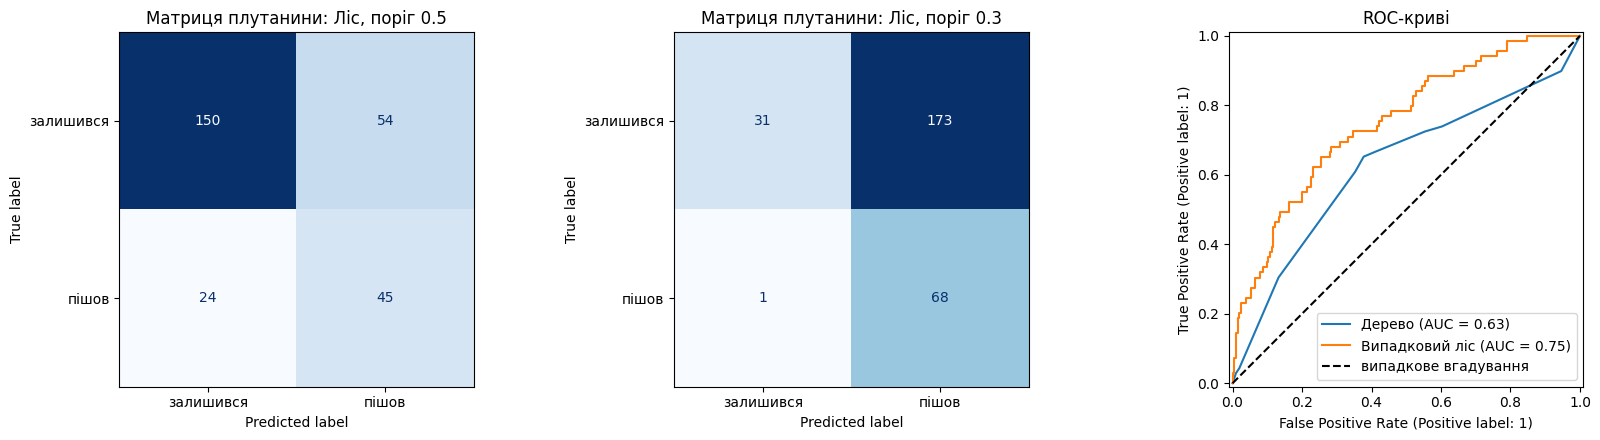

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
pb_rf = rf.predict_proba(X_test)[:, 1]
for a, (title, pr) in zip(ax[:2], [("Ліс, поріг 0.5", (pb_rf >= 0.5).astype(int)),
                                   ("Ліс, поріг 0.3", (pb_rf >= 0.3).astype(int))]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pr), display_labels=["залишився", "пішов"]).plot(
        cmap="Blues", ax=a, colorbar=False)
    a.set_title(f"Матриця плутанини: {title}")
RocCurveDisplay.from_estimator(base, X_test, y_test, ax=ax[2], name="Дерево")
RocCurveDisplay.from_estimator(rf, X_test, y_test, ax=ax[2], name="Випадковий ліс")
ax[2].plot([0, 1], [0, 1], "k--", label="випадкове вгадування"); ax[2].legend(); ax[2].set_title("ROC-криві")
plt.tight_layout(); plt.show()

Важливість ознак (випадковий ліс):
nps                   0.218
support_tickets       0.179
sessions_per_month    0.146
age                   0.099
tenure_months         0.085
avg_session_min       0.082
late_payments         0.063
courses_started       0.034
discount              0.034
courses_completed     0.027
device_мобільний      0.013
city_size_середнє     0.010
city_size_мале        0.010


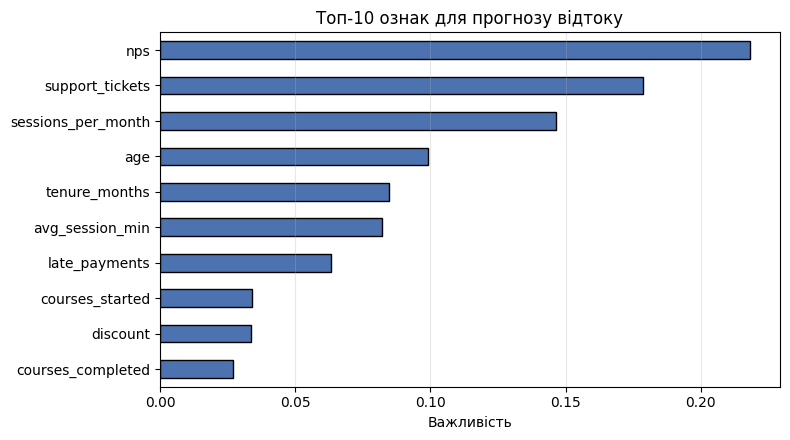

In [18]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Важливість ознак (випадковий ліс):")
print(imp.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
imp.head(10).plot.barh(ax=ax, color="#4C72B0", edgecolor="k")
ax.invert_yaxis(); ax.set_title("Топ-10 ознак для прогнозу відтоку"); ax.set_xlabel("Важливість")
ax.grid(axis="x", alpha=0.3); plt.tight_layout(); plt.show()

In [19]:
# Напрям впливу 5 головних ознак: середні значення у тих, хто пішов, і тих, хто залишився
top5 = imp.head(5).index
base_df.groupby("churn")[list(top5)].mean().round(2).rename(index={0: "залишився", 1: "пішов"})

,nps,support_tickets,sessions_per_month,age,tenure_months
churn,,,,,
залишився,7.34,0.51,9.20,38.48,24.31
пішов,6.05,0.91,7.61,36.84,22.37


In [20]:
# Сегменти із завдання №2: частка відтоку і прогнозована ймовірність для клієнтів базового тарифу.
# Ймовірність отримуємо через cross_val_predict, щоб кожен клієнт оцінювався моделлю, яка його не бачила.
base_df["p_churn"] = cross_val_predict(rf, X, y, cv=skf, method="predict_proba")[:, 1]
seg_risk = base_df.groupby("segment").agg(
    клієнтів=("churn", "size"),
    частка_відтоку=("churn", "mean"),
    сер_ймовірність=("p_churn", "mean"),
    у_групі_ризику=("p_churn", lambda s: (s >= 0.5).sum())).round(3)
seg_risk.sort_values("сер_ймовірність", ascending=False)

,клієнтів,частка_відтоку,сер_ймовірність,у_групі_ризику
segment,,,,
Незадоволені пасивні,214,0.383,0.521,128
Старші новачки,276,0.254,0.438,87
Молоде активне ядро,203,0.177,0.419,52
Досвідчені лояльні,217,0.198,0.418,69


In [21]:
# Для порівняння — частка відтоку в сегментах по всіх 2000 клієнтах
df.groupby("segment")["churn"].agg(["size", "mean"]).round(3).sort_values("mean", ascending=False)

,size,mean
segment,,
Незадоволені пасивні,412,0.345
Старші новачки,550,0.242
Досвідчені лояльні,519,0.160
Молоде активне ядро,519,0.141
